In [57]:
%pip install -q pandas tensorflow numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Deep Learning for Function Estimation
### Amir, 2025, NUS SoC ACE

#### We'll try to estimate the quality of red wine samples based on their physical and chemical features
#### We compute and report the mean absolute error, MAE

In [65]:
# CNN version
# Regression Example With wine dataset ...
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt


In [66]:
# mounting the Google drive
# from google.colab import drive

# drive.mount('/content/drive')

# # Load the dataset
# fp = "/content/drive/My Drive/emeritus/2025/Module2-3/wine_r2_t_noheader.csv"
fp = "wine_r2_t_noheader.csv"

In [67]:

# load dataset to a Pandas dataframe
dataframe = read_csv(fp , header=None)
# copy only values to a numpy n dimensional array, ndarray
dataset = dataframe.values

# split into input (X) and output (Y) variables
X = dataset[:,0:11]
Y = dataset[:,11]

print(X.shape)
# X = X.reshape(X.shape[0], X.shape[1], 1)
# print(X.shape)


(1599, 11)


In [68]:
print(type(dataset))
print(dataset.shape)
print(dataframe.describe())
print( dataframe.head() )

<class 'numpy.ndarray'>
(1599, 12)
                0            1            2            3            4   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean      8.319637     0.527821     0.270976     2.538806     0.087467   
std       1.741096     0.179060     0.194801     1.409928     0.047065   
min       4.600000     0.120000     0.000000     0.900000     0.012000   
25%       7.100000     0.390000     0.090000     1.900000     0.070000   
50%       7.900000     0.520000     0.260000     2.200000     0.079000   
75%       9.200000     0.640000     0.420000     2.600000     0.090000   
max      15.900000     1.580000     1.000000    15.500000     0.611000   

                5            6            7            8            9   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean     15.874922    46.467792     0.996747     3.311113     0.658149   
std      10.460157    32.895324     0.001887     0.154386     0.169507   
mi

In [69]:
# define base model, a deep covolutional one
# structure comprisses 2 1d convolution layers with 16 and 12 filters, filters are 3x1
# then maxpooling for downsampling, a fully connected dense layer with 12 neurons
# Droput layer with 20% at the end
#
def baseline_model():
    # create model
    model = Sequential()
    model.add(Conv1D(16, 3, activation="relu", input_shape=(11,1)))
    model.add(Conv1D(12, 3, activation="relu"))
    model.add(MaxPooling1D())
    model.add(Flatten())
    model.add(Dense(12, input_dim=8, kernel_initializer='normal', activation='relu'))
    model.add( Dropout(0.2) )
    model.add(Dense(1, kernel_initializer='normal'))
    # Compile model
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model


In [70]:
# splitting the train and test subsets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((1279, 11), (320, 11), (1279,), (320,))

In [71]:
# normalization
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Standardize X_train and X_test
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)
Y_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed
Y_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))

X_train_scaled.shape, X_test_scaled.shape

((1279, 11), (320, 11))

In [72]:
# training the model for 900 epochs and testing the trained model with the training data
# we report the training error
estimator = baseline_model()
estimator.fit(X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1), Y_train_scaled, epochs=900, verbose=2)
prediction_scaled = estimator.predict(X_train_scaled)

prediction = scaler_y.inverse_transform(prediction_scaled)

train_error =  np.abs(Y_train - prediction)
mean_error = np.mean(train_error)
min_error = np.min(train_error)
max_error = np.max(train_error)
std_error = np.std(train_error)
# print('\nTraining results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

print('\nTraining results:')
print('MAE =', mean_error)
print('Min error =', min_error)
print('Max error =', max_error)
print('STD error =', std_error)

print('\SKLearn MAE:', mean_absolute_error(Y_train, prediction))

Epoch 1/900


<>:22: SyntaxWarning: invalid escape sequence '\S'
<>:22: SyntaxWarning: invalid escape sequence '\S'
/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_34284/3280440850.py:22: SyntaxWarning: invalid escape sequence '\S'
  print('\SKLearn MAE:', mean_absolute_error(Y_train, prediction))
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_reg

40/40 - 0s - 8ms/step - loss: 0.9979
Epoch 2/900
40/40 - 0s - 888us/step - loss: 0.9824
Epoch 3/900
40/40 - 0s - 762us/step - loss: 0.9433
Epoch 4/900
40/40 - 0s - 694us/step - loss: 0.8634
Epoch 5/900
40/40 - 0s - 713us/step - loss: 0.7924
Epoch 6/900
40/40 - 0s - 694us/step - loss: 0.7656
Epoch 7/900
40/40 - 0s - 704us/step - loss: 0.7523
Epoch 8/900
40/40 - 0s - 680us/step - loss: 0.7358
Epoch 9/900
40/40 - 0s - 678us/step - loss: 0.7363
Epoch 10/900
40/40 - 0s - 676us/step - loss: 0.7185
Epoch 11/900
40/40 - 0s - 685us/step - loss: 0.7044
Epoch 12/900
40/40 - 0s - 849us/step - loss: 0.7010
Epoch 13/900
40/40 - 0s - 776us/step - loss: 0.6910
Epoch 14/900
40/40 - 0s - 800us/step - loss: 0.6863
Epoch 15/900
40/40 - 0s - 734us/step - loss: 0.6842
Epoch 16/900
40/40 - 0s - 706us/step - loss: 0.6856
Epoch 17/900
40/40 - 0s - 678us/step - loss: 0.6742
Epoch 18/900
40/40 - 0s - 661us/step - loss: 0.6822
Epoch 19/900
40/40 - 0s - 652us/step - loss: 0.6793
Epoch 20/900
40/40 - 0s - 662us/ste

In [73]:
# showing the real and predicted quality scores for the training data
df = pd.DataFrame({'Actual': Y_train, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

      Actual  Predicted
1254     6.0   5.562443
1255     6.0   5.931027
1256     5.0   5.028439
1257     5.0   4.793613
1258     6.0   5.346228
1259     5.0   4.763430
1260     5.0   5.200733
1261     5.0   5.296479
1262     6.0   5.888306
1263     6.0   6.202744
1264     5.0   4.928851
1265     5.0   5.739911
1266     5.0   5.167148
1267     4.0   4.385002
1268     5.0   5.065019
1269     6.0   5.897109
1270     6.0   5.898995
1271     6.0   6.293586
1272     6.0   6.201911
1273     5.0   4.964188
1274     5.0   4.730607
1275     5.0   5.212081
1276     6.0   5.656596
1277     6.0   6.133965
1278     5.0   4.857549


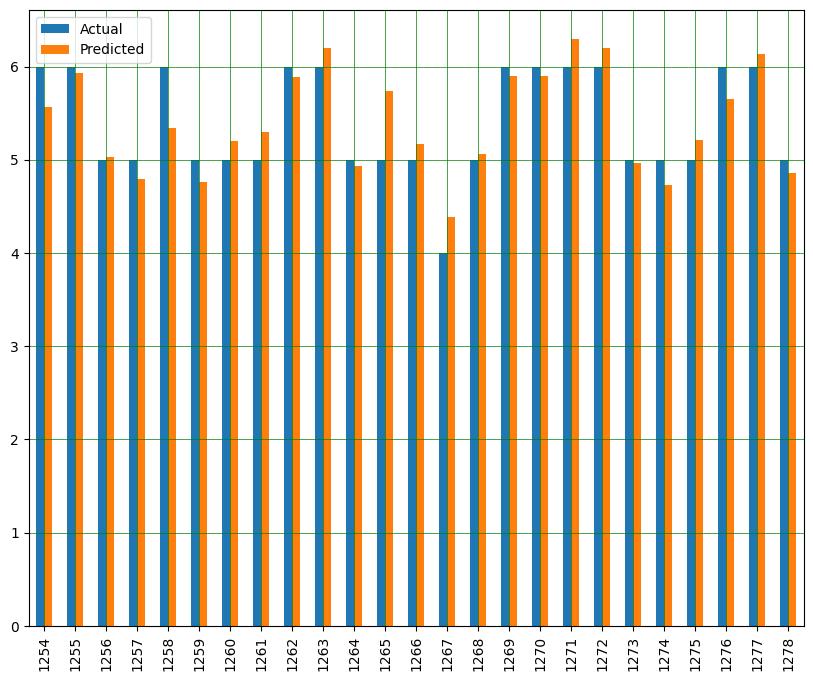

In [74]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

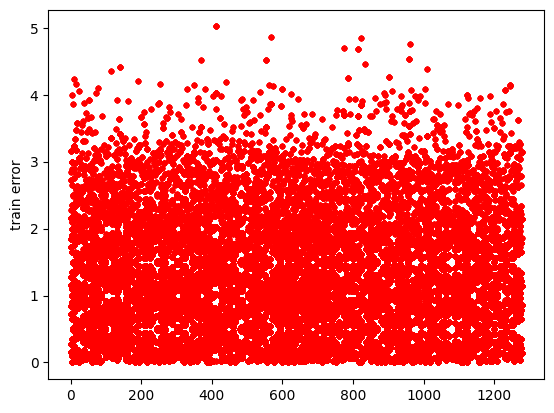

In [75]:
plt.plot(train_error,'r.')
plt.ylabel('train error')
plt.show()

In [77]:
# testing the model with the test data
prediction_scaled = estimator.predict(X_test_scaled)

prediction = scaler_y.inverse_transform(prediction_scaled)

test_error =  np.abs(Y_test - prediction)
mean_error = np.mean(test_error)
min_error = np.min(test_error)
max_error = np.max(test_error)
std_error = np.std(test_error)
print('\nTesting results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)
print('SKLearn MAE:', mean_absolute_error(Y_test, prediction))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step

Testing results:
mean= 0.7758537778072059 
min= 0.00020456314086914062 
max= 4.523565292358398 
std= 0.5925062723283994
SKLearn MAE: 0.5074297234416008


In [78]:
# and showing the results
df = pd.DataFrame({'Actual': Y_test, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

     Actual  Predicted
295     6.0   6.009159
296     6.0   5.391117
297     5.0   6.691790
298     6.0   5.243308
299     5.0   5.080490
300     6.0   6.027567
301     5.0   4.873700
302     6.0   5.354850
303     6.0   5.054555
304     6.0   5.539316
305     6.0   5.886265
306     5.0   4.777988
307     5.0   4.648678
308     6.0   4.917972
309     5.0   5.270772
310     5.0   5.404018
311     6.0   5.878051
312     5.0   5.135129
313     5.0   4.880394
314     5.0   4.167569
315     6.0   5.201517
316     4.0   5.417160
317     5.0   6.549522
318     4.0   4.995630
319     6.0   5.943582


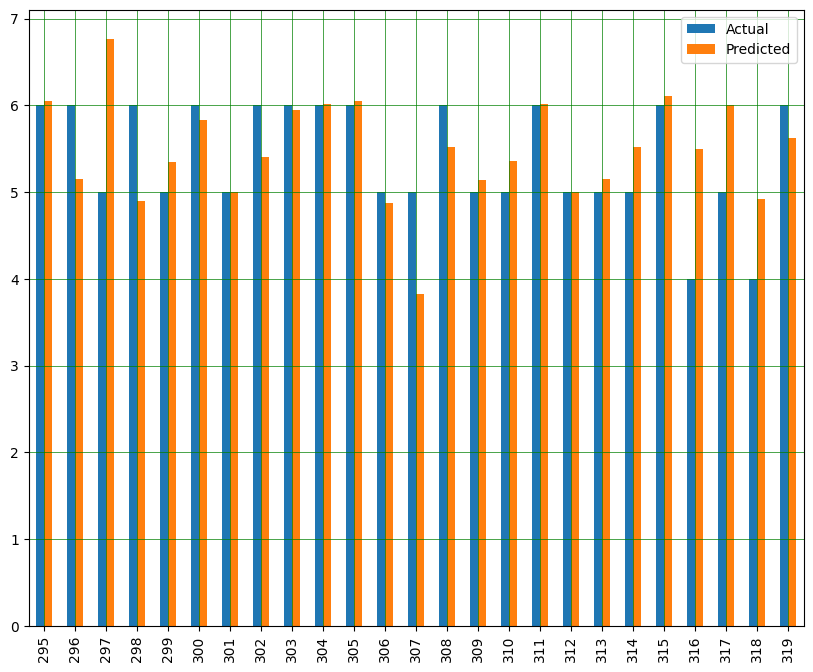

In [45]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

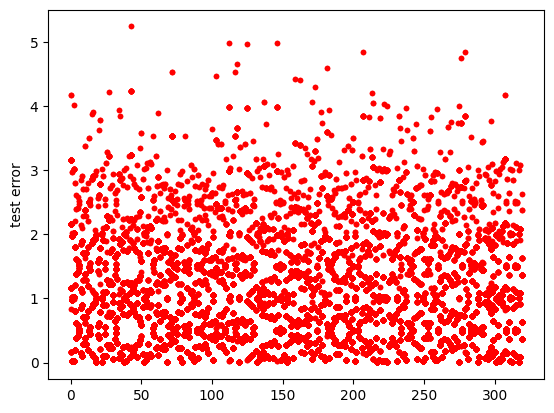

In [46]:
plt.plot(test_error,'r.')
plt.ylabel('test error')
plt.show()

##  Practices
1. train the model for 1400 epochs. what are the training and testing MAE?
2. repeat that with 6000 training epochs. what are the training and testing MAE?
3. move back to 900 training epochs. add two convolutional and one dense layer with the same features of the layers used. what are the training and testing MAE?
4. go for 6000 training epochs. Do you feel any overfitting?
5. set back everything to the original setting, then try to normalize the training and testing features and outputs using standard_scaler. Then see if anything gets better or not. You may use insttructions like what you can see in the next cell.  

#### points:
- use GPU as your runtime type
- if the notebook overflows, change the verbose to 0, e.g. verbose=0 in the training cell.

In [47]:
'''
# normalization
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Standardize X_train and X_test
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)
y_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed
y_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))
'''

'\n# normalization\nfrom sklearn.preprocessing import StandardScaler\n\n# Create scalers\nscaler_X = StandardScaler()\nscaler_y = StandardScaler()\n\n# Standardize X_train and X_test\nX_train_scaled = scaler_X.fit_transform(X_train)\nX_test_scaled = scaler_X.transform(X_test)\n\n# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)\ny_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed\ny_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))\n'